In [ ]:
'''
in this notebook we'll figure out the coordinates of where star-streaks start
'''

In [21]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
import os
import pandas as pd
import review_findings_functions as rff
from scipy.optimize import minimize

In [2]:
fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/1019_minus_extras/"
fpath2 = "/lustre/lrspec/ZTF_data/2022/1019/"
fname = "ztf_20221019449815_000561_zg_c03_x_0025.fits.fz"
fname1 = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/1019_minus_extras/ztf_20221019449815_000561_zg_c03_x_0000.fits.fz"
fname2 = "ztf_20221019449815_000561_zg_c03_x.fits.fz"
path = fpath2 + fname2
hdul = fits.open(path)
file1_array = hdul[1].data

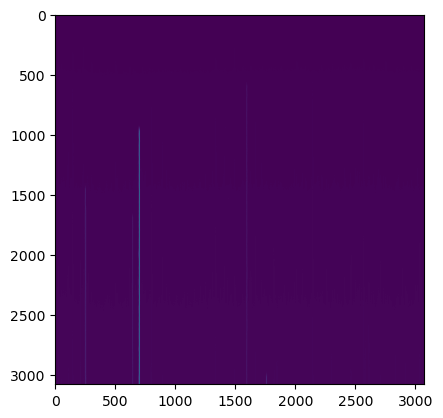

In [78]:
plt.imshow(file1_array)
#we want the ten brightest streaks here
# plt.hist(file1_array)

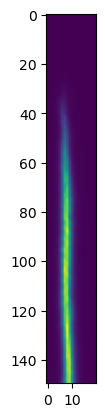

In [3]:
plt.imshow(file1_array[900:1050, 693 : 693 + 20])

In [9]:
tot, maxcols = rff.get_tot_streak(file1_array, 703)

In [66]:
def piecewise_function(xes, first_transition, second_transition, background_val, final_val):
    slope = (final_val-background_val)/(second_transition-first_transition)
    output_array = np.zeros(len(xes))
    for i, x in enumerate(xes):
        # print(x)
        # print(first_transition)
        if x<first_transition:
            
            val = background_val
        elif x<second_transition:
            val =  (x-first_transition)*slope
        else:
            val = final_val
        output_array[i] = val
    return output_array


In [55]:
piecewise_function(args)

0.0
928
1.0
928
2.0
928
3.0
928
4.0
928
5.0
928
6.0
928
7.0
928
8.0
928
9.0
928
10.0
928
11.0
928
12.0
928
13.0
928
14.0
928
15.0
928
16.0
928
17.0
928
18.0
928
19.0
928
20.0
928
21.0
928
22.0
928
23.0
928
24.0
928
25.0
928
26.0
928
27.0
928
28.0
928
29.0
928
30.0
928
31.0
928
32.0
928
33.0
928
34.0
928
35.0
928
36.0
928
37.0
928
38.0
928
39.0
928
40.0
928
41.0
928
42.0
928
43.0
928
44.0
928
45.0
928
46.0
928
47.0
928
48.0
928
49.0
928
50.0
928
51.0
928
52.0
928
53.0
928
54.0
928
55.0
928
56.0
928
57.0
928
58.0
928
59.0
928
60.0
928
61.0
928
62.0
928
63.0
928
64.0
928
65.0
928
66.0
928
67.0
928
68.0
928
69.0
928
70.0
928
71.0
928
72.0
928
73.0
928
74.0
928
75.0
928
76.0
928
77.0
928
78.0
928
79.0
928
80.0
928
81.0
928
82.0
928
83.0
928
84.0
928
85.0
928
86.0
928
87.0
928
88.0
928
89.0
928
90.0
928
91.0
928
92.0
928
93.0
928
94.0
928
95.0
928
96.0
928
97.0
928
98.0
928
99.0
928
100.0
928
101.0
928
102.0
928
103.0
928
104.0
928
105.0
928
106.0
928
107.0
928
108.0
928
109.0
928
110.0
928


array([    0.        ,     0.        ,     0.        , ...,
       14144.47558594, 14144.47558594, 14144.47558594])

In [60]:
# Define the objective function
def function_to_minimize(params, real_vals, xes):
    # Unpack parameters
    first_transition, second_transition, background_val, final_val = params

    # Compute the model's output
    model_output = piecewise_function(xes, first_transition, second_transition, background_val, final_val)

    # Calculate the residuals between x and model_output
    residuals = np.abs(real_vals - model_output)

    # Return an aggregated value (e.g., sum of residuals)
    return np.sum(residuals)  # this is L1, could do difference of squares

In [53]:
def get_guess(tot):
    background_val = 0
    final_val = np.max(tot)
    first_transition = np.where(tot>100)[0][0]
    second_transition = first_transition+75
    return first_transition,second_transition,background_val,final_val

In [52]:
np.where(tot>np.average(tot))[0][0]

966

In [70]:
xes = np.linspace(0, len(tot)-1, len(tot))
initial_guess = get_guess(tot)


In [69]:
len(xes)

3081

In [71]:
# Minimization
result = minimize(function_to_minimize, initial_guess, args=(tot, xes))

In [73]:
#first_transition, second_transition, background_val, final_val

# Extract optimized parameters
optimized_first_transition = result.x[0]
optimized_second_transition = result.x[1]
optimized_background_val = result.x[2]
optimized_final_val = result.x[3]

print("Optimized first_transition:", optimized_first_transition)
print("Optimized optimized_second_transition:", optimized_second_transition)
print("optimized_background_val:", optimized_background_val)
print("optimized_final_val:", optimized_final_val)
print("Minimum value:", result.fun)

Optimized first_transition: 933.6076104959001
Optimized optimized_second_transition: 981.968029464267
optimized_background_val: -117.46110891533233
optimized_final_val: 12754.176509001392
Minimum value: 666419.9609691615


In [36]:
np.shape(args)

(5,)

In [58]:
len(tot)

3080

Text(0.5, 1.0, 'fitting of a piecewise function to the beginning of star streaks')

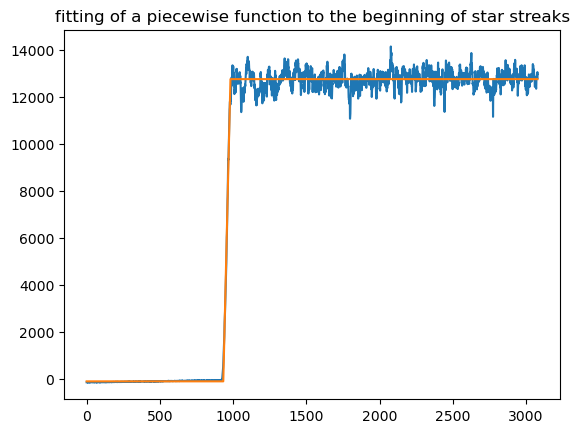

In [75]:
plt.plot(tot, label='data')
plt.plot(xes, piecewise_function(xes, optimized_first_transition, optimized_second_transition,
                                optimized_background_val,optimized_final_val), label='fit')
plt.title("fitting of a piecewise function to the beginning of star streaks")

In [80]:
image = file1_array

In [85]:
#this is what i did when i implanted them

# short list of where brightest streaks are
averages = np.average(image, axis=0)
sorted = np.argsort(averages)[-50:] #had it at 20 originally, but should be 5*10
doublesorted = np.sort(sorted)
shortlist = []
for i, el in enumerate(doublesorted):
    ihatenumbers = np.hstack((doublesorted, [0]))
    if ihatenumbers[i + 1] != el + 1:
        shortlist.append(el)

In [86]:
shortlist

[149, 255, 262, 648, 707, 804, 1338, 1600, 1760, 2147, 2569]

In [88]:
np.zeros((len(shortlist),4))

array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.]])

In [90]:
results = np.zeros((len(shortlist),5))
for i, coord in enumerate(shortlist):
    tot, maxcols = rff.get_tot_streak(file1_array, coord-3) #because it's saves the highest col val in each streak
    initial_guess = get_guess(tot)
    result = minimize(function_to_minimize, initial_guess, args=(tot, xes))
    optimized_first_transition = result.x[0]
    optimized_second_transition = result.x[1]
    optimized_background_val = result.x[2]
    optimized_final_val = result.x[3]
    results[i] = coord, optimized_first_transition, optimized_second_transition, optimized_background_val, optimized_final_val

In [91]:
results

array([[ 1.49000000e+02,  2.75510156e+02,  4.86375321e+03,
        -1.44836415e+02,  3.38070445e+02],
       [ 2.55000000e+02,  1.42124316e+03,  1.46995001e+03,
        -8.97776270e+01,  2.58447843e+03],
       [ 2.62000000e+02,  1.42125012e+03,  1.46989954e+03,
        -8.93007329e+01,  2.58458772e+03],
       [ 6.48000000e+02,  1.65192219e+03,  1.70432064e+03,
        -7.70324121e+01,  1.71972070e+03],
       [ 7.07000000e+02,  9.33575612e+02,  9.81971534e+02,
        -1.17130691e+02,  1.27544438e+04],
       [ 8.04000000e+02,  5.61867105e+02,  3.18229535e+03,
        -1.45248490e+02,  1.99691503e+02],
       [ 1.33800000e+03,  4.77715900e+02,  4.99683639e+03,
        -1.35667255e+02,  3.20214929e+02],
       [ 1.60000000e+03,  5.60814505e+02,  6.21531547e+02,
        -1.33320254e+02,  1.63324966e+03],
       [ 1.76000000e+03,  4.89474197e+03,  5.59114047e+03,
         5.05055065e+00,  2.80983749e+03],
       [ 2.14700000e+03,  3.06907864e+02,  3.08878809e+03,
        -1.43016404e+02

In [92]:
positions = results[:,1]

In [93]:
positions

array([ 275.51015649, 1421.24316134, 1421.25012192, 1651.92218522,
        933.57561217,  561.8671053 ,  477.71590038,  560.81450495,
       4894.74197213,  306.90786409,  922.36649898])

In [4]:
hdr = hdul[1].header

In [22]:
hdr

XTENSION= 'IMAGE   '           / IMAGE extension                                
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 3072 / length of data axis 1                          
NAXIS2  =                 3080 / length of data axis 2                          
PCOUNT  =                    0 / required keyword; must = 0                     
GCOUNT  =                    1 / required keyword; must = 1                     
EXTNAME = '1       '                                                            
HDUVERS =                    1                                                  
CCD_ID  =                    3 / ID value of CCD detector                       
CCDNAME = 'S03     '           / Detector name or serial number                 
AMP_ID  =                    0 / ID value of CCD amplifier                      
AMP_NAME= 'F       '        